# Advanced LangChain & LangGraph: Building Intelligent Workflows

This notebook covers the transition from simple LLM chains to complex, state-driven agentic workflows using **LangChain** and **LangGraph**.

### Core Concepts:
- **LangChain**: A framework for "chaining" together different computational steps (Runnables).
- **LangGraph**: An extension of LangChain for building stateful, multi-actor applications with cyclic graphs.

## 1. Setup and Environment Configuration
First, we install the necessary libraries and configure our API keys for **Groq**, **Anthropic**, and **LangSmith**.

In [1]:
# Install core dependencies
# !pip install -U python-dotenv langchain langchain-groq langchain-anthropic langgraph langsmith

In [2]:
import os

# --------------------------------------------------------------
# 1. API KEY CONFIGISTRATION
# --------------------------------------------------------------

# Groq API Key (Model Provider)
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

# Anthropic API Key (Claude Models)
os.environ["ANTHROPIC_API_KEY"] = os.getenv("ANTHROPIC_API_KEY")

# --------------------------------------------------------------
# 2. LANGSMITH TRACING (Observability)
# --------------------------------------------------------------

# Turn on tracing to see detailed logs in LangSmith
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGSMITH_PROJECT"] = "LangGraph_Interactive_Learning"

# NOTE: You must provide your own LANGCHAIN_API_KEY for tracing to work
# os.environ["LANGCHAIN_API_KEY"] = "your_langchain_api_key_here"

print("Environment variables set successfully.")

Environment variables set successfully.


## 2. Using Chat Models
Chat models are the core engine. We'll use `init_chat_model` for a flexible way to instantiate different providers.

In [3]:
from langchain.chat_models import init_chat_model

# Initialize a model from Groq (Llama 3.1 8B)
model = init_chat_model(
    "llama-3.1-8b-instant",
    model_provider="groq"
)

# Basic invocation
response = model.invoke("What is the capital of France?")
print("LLM Response:", response.content)

c:\conda\envs\agentai\Lib\site-packages\langsmith\client.py:498: LangSmithMissingAPIKeyWarning: API key must be provided when using hosted LangSmith API
  warnings.warn(


LLM Response: The capital of France is Paris.


## 3. Message Types and Context
LangChain uses structured messages to handle conversation history and instructions.
- `SystemMessage`: General instructions for the AI.
- `HumanMessage`: Input from the user.
- `AIMessage`: Output from the model.

In [4]:
from langchain_core.messages import HumanMessage, SystemMessage

messages = [
    SystemMessage(content="You are a helpful travel assistant. Always respond with a friendly tone."),
    HumanMessage(content="Suggest a beach destination in India for December.")
]

response = model.invoke(messages)
print(response.content)

Failed to multipart ingest runs: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c26-6299-7001-84b0-e11e85c768b3,id=019c2c26-6299-7001-84b0-e11e85c768b3


December is a great time to visit the beach destinations in India, and there are many options to choose from. One of my top picks would be:

**Goa**

Goa is a tropical paradise on India's west coast, known for its stunning beaches, vibrant culture, and mouth-watering seafood. In December, the weather in Goa is perfect - warm and sunny, with average temperatures ranging from 24°C to 30°C (75°F to 86°F). The beaches are less crowded than during the peak summer months, making it an ideal time to enjoy the sun, sand, and surf.

Some of the top beaches in Goa include:

* **Baga Beach**: A popular beach with crystal-clear waters and powdery white sand.
* **Calangute Beach**: A long stretch of beach with calm waters and a lively atmosphere.
* **Palolem Beach**: A picturesque beach in South Goa, known for its scenic views and tranquil atmosphere.

Goa also offers a range of activities, including water sports, snorkeling, and dolphin-watching. You can also explore the local culture by visiting 

## 4. Prompt Templates and Chaining (LCEL)
Prompt templates allow for dynamic inputs. **LCEL (LangChain Expression Language)** uses the pipe operator `|` to chain components effortlessly.

In [5]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# 1. Define a template with placeholders
prompt_template = ChatPromptTemplate.from_template(
    "Provide only ONE word for a famous place to visit in {country} in the month of {month}."
)

# 2. Build the chain using LCEL
# Flow: Input -> Prompt -> Model -> String Parser -> Output
chain = prompt_template | model | StrOutputParser()

destination = chain.invoke({"country": "India", "month": "June"})
print(f"Target Destination: {destination}")

Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c26-6299-7001-84b0-e11e85c768b3,id=019c2c26-6299-7001-84b0-e11e85c768b3; trace=019c2c26-76a5-7060-9df6-eb960006ff5a,id=019c2c26-76a5-7060-9df6-eb960006ff5a


Target Destination: Goa.


### Creating Composite Chains
We can nest chains to perform multistep logic. For example, finding a destination and then generating an itinerary.

In [6]:
itinerary_prompt = ChatPromptTemplate.from_template("Create a 3-day travel itinerary for {destination}.")

# Chain composition
# We pass the output of the first chain as the input to the next prompt
composed_chain = {"destination": chain} | itinerary_prompt | model | StrOutputParser()

itinerary = composed_chain.invoke({"country": "Japan", "month": "April"})
print(itinerary)

**Hanami Travel Itinerary (3 Days)**

**What is Hanami?**
Hanami is the traditional Japanese practice of cherry blossom viewing, which typically takes place in late March to early May. During this time, Japan's beautiful cherry blossoms (sakura) are in full bloom. This 3-day itinerary will guide you to some of Japan's most famous Hanami spots.

**Day 1: Tokyo**

* **Morning:** Visit the famous **Ueno Park** in Tokyo, which is home to over 1,000 cherry blossom trees. Arrive early to avoid the crowds and enjoy the serene atmosphere.
* **Lunch:** Try traditional Japanese cuisine at a local restaurant near the park.
* **Afternoon:** Visit the **Shinjuku Gyoen National Garden**, another popular spot for Hanami. The garden features a variety of cherry blossom trees, as well as other flowers and scenic walking paths.
* **Evening:** Explore the trendy **Harajuku** district and enjoy the vibrant street food and shopping scene.

**Day 2: Tokyo to Nikko (Day Trip)**

* **Morning:** Take a day tri

## 5. Introduction to LangGraph
LangGraph allows us to build stateful workflows using a graph structure where nodes are functions and edges define the flow.

In [7]:
from typing import TypedDict, Optional
from langgraph.graph import StateGraph, START, END

# 1. Define the State structure
class BasicState(TypedDict):
    x: int
    y: int
    result: Optional[int]

# 2. Define Node functions
def add_node(state: BasicState):
    print("--- (Node: Add) ---")
    return {"result": state['x'] + state['y']}

def multiply_node(state: BasicState):
    print("--- (Node: Multiply) ---")
    return {"result": state['result'] * 2}

# 3. Build the Graph
workflow = StateGraph(BasicState)
workflow.add_node("adder", add_node)
workflow.add_node("multiplier", multiply_node)

workflow.add_edge(START, "adder")
workflow.add_edge("adder", "multiplier")
workflow.add_edge("multiplier", END)

# 4. Compile and Run
app = workflow.compile()
output = app.invoke({"x": 10, "y": 5})
print("Final output:", output)

--- (Node: Add) ---
--- (Node: Multiply) ---
Final output: {'x': 10, 'y': 5, 'result': 30}


## 6. Advanced Application: Intelligent Customer Support Router
In this section, we build a system that:
1. Categorizes a customer query.
2. Analyzes sentiment.
3. Routes to different handlers based on category and sentiment (Escalation logic).

In [8]:
from typing import TypedDict, Dict
from typing_extensions import Annotated

# The State for our support system
class SupportState(TypedDict):
    query: str
    category: str
    sentiment: str
    response: str

# --- Nodes ---

def categorize_query(state: SupportState):
    prompt = ChatPromptTemplate.from_template(
        "Categorize the following query into exactly one of these: Technical, Billing, General. Query: {query}"
    )
    category = (prompt | model | StrOutputParser()).invoke({"query": state["query"]})
    return {"category": category.strip()}

def analyze_sentiment(state: SupportState):
    prompt = ChatPromptTemplate.from_template(
        "Analyze the sentiment. Respond with exactly one word: Positive, Neutral, or Negative. Query: {query}"
    )
    sentiment = (prompt | model | StrOutputParser()).invoke({"query": state["query"]})
    return {"sentiment": sentiment.strip()}

def technical_handler(state: SupportState):
    return {"response": "Our tech team is looking into: " + state["query"]}

def billing_handler(state: SupportState):
    return {"response": "Billing inquiries usually take 24h. Query: " + state["query"]}

def general_handler(state: SupportState):
    return {"response": "Thank you for reaching out! Regarding: " + state["query"]}

def escalation_node(state: SupportState):
    return {"response": "[ESCALATED] A human agent will contact you immediately."}

# --- Routing Logic ---

def router(state: SupportState):
    # If sentiment is negative, always escalate
    if "Negative" in state["sentiment"]:
        return "escalate"
    
    # Otherwise route based on category
    cat = state["category"].lower()
    if "technical" in cat:
        return "tech"
    elif "billing" in cat:
        return "billing"
    else:
        return "general"

### Assembling the Graph

In [9]:
builder = StateGraph(SupportState)

builder.add_node("categorizer", categorize_query)
builder.add_node("sentiment_analyzer", analyze_sentiment)
builder.add_node("technical_handler", technical_handler)
builder.add_node("billing_handler", billing_handler)
builder.add_node("general_handler", general_handler)
builder.add_node("escalator", escalation_node)

# Sequence
builder.add_edge(START, "categorizer")
builder.add_edge("categorizer", "sentiment_analyzer")

# Conditional Routing from sentiment_analyzer
builder.add_conditional_edges(
    "sentiment_analyzer",
    router,
    {
        "escalate": "escalator",
        "tech": "technical_handler",
        "billing": "billing_handler",
        "general": "general_handler"
    }
)

# Endings
builder.add_edge("technical_handler", END)
builder.add_edge("billing_handler", END)
builder.add_edge("general_handler", END)
builder.add_edge("escalator", END)

support_app = builder.compile()

Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c26-76a5-7060-9df6-eb960006ff5a,id=019c2c26-76a5-7060-9df6-eb960006ff5a; trace=019c2c26-8127-7d90-b9cd-10cfaacd2731,id=019c2c26-8127-7d90-b9cd-10cfaacd2731; trace=019c2c26-8127-7d90-b9cd-10cfaacd2731,id=019c2c26-8128-7291-8ac1-d5009dc37353; trace=019c2c26-8127-7d90-b9cd-10cfaacd2731,id=019c2c26-8128-7291-8ac1-d5009dc37353; trace=019c2c26-8127-7d90-b9cd-10cfaacd2731,id=019c2c26-8231-7e40-9f4b-0909afff751d; trace=019c2c26-8127-7d90-b9cd-10cfaacd2731,id=019c2c26-8231-7e40-9f4b-0909afff751d; trace=019c2c26-8127-7d90-b9cd-10cfaacd2731,id=019c2c26-8758-78d3-9a6a-6b606a0b78d2; trace=019c2c26-8127-7d90-b9cd-10cfaacd2731,id=019c2c26-8758-78d3-9a6a-6b606a0b78d2; trace=019c2c26-8127-7d90-b9cd-10cfaacd2731,id

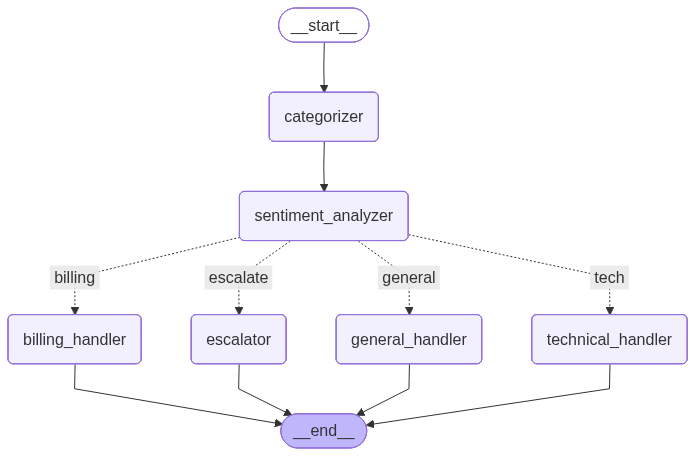

In [10]:
from IPython.display import Image, display

try:
    display(Image(support_app.get_graph().draw_mermaid_png()))
except Exception:
    print("Diagram generation skipped (requires optional dependencies).")

In [11]:
# Test Case 1: Negative technical query
res1 = support_app.invoke({"query": "The system crashed and I'm very angry!"})
print(f"Response 1: {res1['response']}")

# Test Case 2: Neutral billing query
res2 = support_app.invoke({"query": "I need my last month's invoice."})
print(f"Response 2: {res2['response']}")

Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c26-8767-7573-b56f-8682e54124db,id=019c2c26-876c-7b50-9ecc-c93d8df5e95a; trace=019c2c26-8767-7573-b56f-8682e54124db,id=019c2c26-8a90-7ac2-b3de-caa5276dad40; trace=019c2c26-8767-7573-b56f-8682e54124db,id=019c2c26-8a90-7ac2-b3de-caa5276dad40; trace=019c2c26-8767-7573-b56f-8682e54124db,id=019c2c26-8769-7bb2-833a-5f589d822e5d; trace=019c2c26-8767-7573-b56f-8682e54124db,id=019c2c26-8768-7c02-bc48-2bb7f87e052d; trace=019c2c26-8767-7573-b56f-8682e54124db,id=019c2c26-8a91-7b23-ab4c-62b7e96df0b1; trace=019c2c26-8767-7573-b56f-8682e54124db,id=019c2c26-8a91-7b23-ab4c-62b7e96df0b1; trace=019c2c26-8767-7573-b56f-8682e54124db,id=019c2c26-8a91-7b23-ab4c-62c87afe39ef; trace=019c2c26-8767-7573-b56f-8682e54124db,id

Response 1: [ESCALATED] A human agent will contact you immediately.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c26-a7db-7260-823a-76d905cbdf23,id=019c2c26-a7db-7260-823a-76d905cbdf23; trace=019c2c26-a7db-7260-823a-76d905cbdf23,id=019c2c26-a7e3-70a2-998b-98578afafd37; trace=019c2c26-a7db-7260-823a-76d905cbdf23,id=019c2c26-a7e5-72a1-bca1-70743a812301; trace=019c2c26-a7db-7260-823a-76d905cbdf23,id=019c2c26-a7e6-7db2-933f-426c7014f389; trace=019c2c26-a7db-7260-823a-76d905cbdf23,id=019c2c26-a7e6-7db2-933f-426c7014f389; trace=019c2c26-a7db-7260-823a-76d905cbdf23,id=019c2c26-a7e9-7700-8591-341fe1efc526; trace=019c2c26-a7db-7260-823a-76d905cbdf23,id=019c2c26-a7e9-7700-8591-341fe1efc526; trace=019c2c26-a7db-7260-823a-76d905cbdf23,id=019c2c26-ae6d-7e50-8613-7012831f55b5; trace=019c2c26-a7db-7260-823a-76d905cbdf23,id

Response 2: Billing inquiries usually take 24h. Query: I need my last month's invoice.


## 7. Interactive Chatbot with Persistent Memory
By using the `add_messages` annotation in the state, LangGraph automatically manages chat history for us, appending new messages instead of overwriting.

In [12]:
from langgraph.graph.message import add_messages
from langchain_anthropic import ChatAnthropic

class ChatState(TypedDict):
    # add_messages ensures messages are appended to the existing history
    messages: Annotated[list, add_messages]

# Use Claude (Anthropic) for the chatbot node
claud_llm = ChatAnthropic(model="claude-3-haiku-20240307")

def chatbot_node(state: ChatState):
    return {"messages": [claud_llm.invoke(state["messages"])]}

chat_builder = StateGraph(ChatState)
chat_builder.add_node("chatbot", chatbot_node)
chat_builder.add_edge(START, "chatbot")
chat_builder.add_edge("chatbot", END)

chat_bot = chat_builder.compile()

In [20]:
def run_chat():
    print("Chatbot initialized. Type 'exit' to stop.")
    config = {"configurable": {"thread_id": "1"}}
    while True:
        user_input = input("User: ")
        if user_input.lower() in ["quit", "exit", "q"]:
            break
        try:
            for event in graph.stream({"messages": [HumanMessage(content=user_input)]}, config=config):
                for value in event.values():
                    print("Assistant:", value["messages"][-1].content)
        except NameError:
            print("Error: 'graph' is not defined. Please run the Memory compilation cell first.")
            break

run_chat() # Commented out here


Chatbot initialized. Type 'exit' to stop.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c27-4455-7d22-b031-483ed2e0b867,id=019c2c27-445b-74f1-b3eb-20c5c7f4174d; trace=019c2c27-4455-7d22-b031-483ed2e0b867,id=019c2c27-445a-7ed2-a51c-ea08b9635877; trace=019c2c27-4455-7d22-b031-483ed2e0b867,id=019c2c27-4455-7d22-b031-483ed2e0b867
Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c27-5970-7dd3-adf7-4ea3be32c69d,id=019c2c27-5970-7dd3-adf7-4ea3be32c69d; trace=019c2c27-5970-7dd3-adf7-4ea3be32c69d,id=019c2c27-5975-7250-ae68-29f1146b2d88; trace=019c2c27-

Assistant: The current Prime Minister of India is Narendra Modi. He has been the Prime Minister of India since May 2014.

Some key facts about the Prime Minister of India:

- Name: Narendra Damodardas Modi
- Political Party: Bharatiya Janata Party (BJP)
- Prime Minister Since: May 2014
- Previously Served as: Chief Minister of Gujarat (2001-2014)

Narendra Modi is the 14th and current Prime Minister of India. He led the BJP-led National Democratic Alliance to a landslide victory in the 2014 general election and was re-elected in 2019. As the head of the executive branch, the Prime Minister is the chief administrative authority of the country.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c27-5970-7dd3-adf7-4ea3be32c69d,id=019c2c27-5975-7250-ae68-2a0a42df1add; trace=019c2c27-5970-7dd3-adf7-4ea3be32c69d,id=019c2c27-5975-7250-ae68-29f1146b2d88; trace=019c2c27-5970-7dd3-adf7-4ea3be32c69d,id=019c2c27-5970-7dd3-adf7-4ea3be32c69d


## 8. Verifying LangSmith Tracing
Check your [LangSmith Dashboard](https://smith.langchain.com/) to see the traces of all invocations from this notebook.

In [21]:
print(f"Tracing Enabled: {os.environ.get('LANGCHAIN_TRACING_V2')}")
print(f"Project Name: {os.environ.get('LANGSMITH_PROJECT')}")

Tracing Enabled: true
Project Name: LangGraph_Interactive_Learning


# `Memory`

In [22]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()
graph = chat_builder.compile(checkpointer=memory)

# Run the chatbot with context!
run_chat()


Chatbot initialized. Type 'exit' to stop.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c27-e998-7161-a03c-5c90b9573870,id=019c2c27-e998-7161-a03c-5c90b9573870; trace=019c2c27-e998-7161-a03c-5c90b9573870,id=019c2c27-e99d-7150-a431-fb0a3f3ea233; trace=019c2c27-e998-7161-a03c-5c90b9573870,id=019c2c27-e99e-7820-a144-b13ebf998e3c


Assistant: I'm afraid I don't have enough information to determine whose age you are asking about. Could you please provide more context about who you are referring to? That would help me better understand and try to answer your question.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c27-e998-7161-a03c-5c90b9573870,id=019c2c27-e99e-7820-a144-b13ebf998e3c; trace=019c2c27-e998-7161-a03c-5c90b9573870,id=019c2c27-e99d-7150-a431-fb0a3f3ea233; trace=019c2c27-e998-7161-a03c-5c90b9573870,id=019c2c27-e998-7161-a03c-5c90b9573870


# `Configuration`

In [16]:
config = {"configurable": {"thread_id": "1"}}

In [17]:
user_input = "Hi there! My name is Will."

# The config is the **second positional argument** to stream() or invoke()!
events = graph.stream(
    {"messages": [{"role": "user", "content": user_input}]},
    config,
    stream_mode="values",
)

for event in events:
    event["messages"][-1].pretty_print()


================================ Human Message =================================

Hi there! My name is Will.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c27-3f44-7402-bc24-ece427e152db,id=019c2c27-3f44-7402-bc24-ece427e152db; trace=019c2c27-3f44-7402-bc24-ece427e152db,id=019c2c27-3f4b-7c33-bb30-9a8cdca73fa7; trace=019c2c27-3f44-7402-bc24-ece427e152db,id=019c2c27-3f4b-7c33-bb30-9a9bae7b5355


================================== Ai Message ==================================

It's nice to meet you, Will! I'm Claude, an AI assistant created by Anthropic. I'm here to help with any questions or tasks you may have. Please let me know if there's anything I can assist you with.


In [18]:
config2 = {"configurable": {"thread_id": "2"}}

In [19]:
user_input = "Do you remember my name?"

# The config is the **second positional argument** to stream() or invoke()!
events = graph.stream(
    {"messages": [{"role": "user", "content": user_input}]},
    config,
    stream_mode="values",
)

for event in events:
    event["messages"][-1].pretty_print()


================================ Human Message =================================

Do you remember my name?


Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c27-3f44-7402-bc24-ece427e152db,id=019c2c27-3f4b-7c33-bb30-9a9bae7b5355; trace=019c2c27-3f44-7402-bc24-ece427e152db,id=019c2c27-3f4b-7c33-bb30-9a8cdca73fa7; trace=019c2c27-3f44-7402-bc24-ece427e152db,id=019c2c27-3f44-7402-bc24-ece427e152db; trace=019c2c27-4455-7d22-b031-483ed2e0b867,id=019c2c27-4455-7d22-b031-483ed2e0b867; trace=019c2c27-4455-7d22-b031-483ed2e0b867,id=019c2c27-445a-7ed2-a51c-ea08b9635877; trace=019c2c27-4455-7d22-b031-483ed2e0b867,id=019c2c27-445b-74f1-b3eb-20c5c7f4174d


================================== Ai Message ==================================

Yes, I remember that your name is Will. As an AI assistant, I try my best to remember details about the humans I interact with in order to provide personalized and helpful service.


# `Adding Web Search Tool`

In [23]:
# Tavily Search
# 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
os.environ['TAVILY_API_KEY'] = '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'

In [ ]:
from langchain_community.tools.tavily_search import TavilySearchResults

tool = TavilySearchResults(max_results=2)  # Scrapping data in real time from internet
tools = [tool]

tool.invoke("tell me about deepseek llm launched in jan 2025")

C:\Users\user\AppData\Local\Temp\ipykernel_20808\162308006.py:3: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tool = TavilySearchResults(max_results=2)
Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c36-9c23-73f2-adac-47682dd6cf76,id=019c2c36-9c23-73f2-adac-47682dd6cf76


[{'title': 'DeepSeek-R1 Overview: Features, Capabilities, Parameters',
  'url': 'https://fireworks.ai/blog/deepseek-r1-deepdive',
  'content': '## Brief Overview of DeepSeek R1\n\nLLM research space is undergoing rapid evolution, with each new model pushing the boundaries of what machines can accomplish. DeepSeek R1, released on January 20, 2025, by DeepSeek, represents a significant leap in the realm of open-source reasoning models. With capabilities rivaling top proprietary solutions, DeepSeek R1 aims to make advanced reasoning, problem-solving, and real-time decision-making more accessible to researchers and developers across the globe.',
  'score': 0.9999509},
 {'title': 'Demystifying DeepSeek | Thoughtworks',
  'url': 'https://www.thoughtworks.com/insights/blog/generative-ai/demystifying-deepseek',
  'content': 'By \n\nPrasanna Pendse\n\nPublished: January 31, 2025\n\nOn January 10, 2025, DeepSeek launched an LLM, R1, that the startup claimed is on par with Open AI’s ChatGPT o1 fo

Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c36-9c23-73f2-adac-47682dd6cf76,id=019c2c36-9c23-73f2-adac-47682dd6cf76


# `ChatBot With Memory and web search tool`

In [29]:
from typing import Annotated
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_core.messages import BaseMessage
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition


class State(TypedDict):
    messages: Annotated[list, add_messages]


graph_builder = StateGraph(State)

tool = TavilySearchResults(max_results=2)
tools = [tool]

llm = ChatAnthropic(model="claude-3-5-sonnet-20240620")
llm_with_tools = llm.bind_tools(tools)


def chatbot(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


graph_builder.add_node("chatbot", chatbot)

tool_node = ToolNode(tools=[tool])
graph_builder.add_node("tools", tool_node)

graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition,
)

# Any time a tool is called, we return to the chatbot to decide the next step
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START, "chatbot")

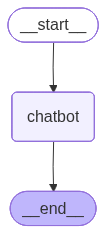

In [30]:
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png())) 
except Exception:
    # This requires some extra dependencies and its optional
    pass   

In [31]:
def run_chat():
    print("Chatbot initialized. Type 'exit' to stop.")
    config = {"configurable": {"thread_id": "1"}}
    while True:
        user_input = input("User: ")
        if user_input.lower() in ["quit", "exit", "q"]:
            break
        try:
            for event in graph.stream({"messages": [HumanMessage(content=user_input)]}, config=config):
                for value in event.values():
                    print("Assistant:", value["messages"][-1].content)
        except NameError:
            print("Error: 'graph' is not defined. Please run the Memory compilation cell first.")
            break

run_chat() # Commented out here


Chatbot initialized. Type 'exit' to stop.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c3f-8382-73b2-b2d9-ad35f194c853,id=019c2c3f-8382-73b2-b2d9-ad35f194c853; trace=019c2c3f-8382-73b2-b2d9-ad35f194c853,id=019c2c3f-847b-7a22-a8b0-8396d7652734; trace=019c2c3f-8382-73b2-b2d9-ad35f194c853,id=019c2c3f-849f-78f3-8ef2-e713d4d6e9f3


Assistant: There is no "Prime Minister" of the United States. The head of the executive branch of the U.S. federal government is the President of the United States, not a Prime Minister.

The current President of the United States is Joe Biden. He assumed office on January 20, 2021 after winning the 2020 presidential election.

The President of the United States is not referred to as the "Prime Minister." That title is used in other countries with parliamentary systems of government, but the U.S. has a presidential system where the President serves as both the head of state and head of government.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c3f-8382-73b2-b2d9-ad35f194c853,id=019c2c3f-849f-78f3-8ef2-e713d4d6e9f3; trace=019c2c3f-8382-73b2-b2d9-ad35f194c853,id=019c2c3f-847b-7a22-a8b0-8396d7652734; trace=019c2c3f-8382-73b2-b2d9-ad35f194c853,id=019c2c3f-8382-73b2-b2d9-ad35f194c853
Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c3f-f816-7183-8acd-4e40f2c50d8a,id=019c2c3f-f816-7183-8acd-4e40f2c50d8a; trace=019c2c3f-f816-7183-8acd-4e40f2c50d8a,id=019c2c3f-f81c-7710-870e-62dab1da58f4; trace=019c2c3f-

Assistant: The current President of the United States is Joe Biden.

Joe Biden was elected as the 46th President of the United States and assumed office on January 20, 2021.

Some key facts about the current U.S. President:

- Name: Joseph Robinette Biden Jr.
- Age: 79 years old (born November 20, 1942)
- Political Party: Democratic Party
- Took office: January 20, 2021
- Running mate/Vice President: Kamala Harris

So in summary, the name of the current President of the United States is Joe Biden.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithAuthError: Authentication failed for https://api.smith.langchain.com/runs/multipart. HTTPError('401 Client Error: Unauthorized for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Unauthorized"}\n')trace=019c2c3f-f816-7183-8acd-4e40f2c50d8a,id=019c2c3f-f81d-73f3-a691-953cd205bbf4; trace=019c2c3f-f816-7183-8acd-4e40f2c50d8a,id=019c2c3f-f81c-7710-870e-62dab1da58f4; trace=019c2c3f-f816-7183-8acd-4e40f2c50d8a,id=019c2c3f-f816-7183-8acd-4e40f2c50d8a
